# Evaluate detection accuracy with the coefficient of determination ($R^2$)

Compares the detector output against the dataset annotation split. The goodness of fit is
measured per OCEAN trait with

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}, \qquad
SS_{res} = \sum_i (y_i - \hat{y}_i)^2, \qquad
SS_{tot} = \sum_i (y_i - \bar{y})^2$$

where $y_i$ is the annotated score, $\hat{y}_i$ is the predicted score and $\bar{y}$ is the
mean of the annotated scores. $R^2 = 1$ is a perfect fit; $R^2 \le 0$ means the model is no
better than predicting the mean.

Inputs:
- annotations : `first-impressions/annotations/test-annotation/annotation_test.pkl`
  (`{trait: {filename: score}}`)
- predictions : newest `results/test_detections/detection_*.csv`, or a fresh detection run
  over `first-impressions/test` when `RUN_FRESH_DETECTION` is enabled

Outputs are written to `results/eval_r2/`: the matched rows, the $R^2$ summary table and a
scatter plot per trait/modality.


In [8]:
import glob
import os
import pickle
import sys
import time

import numpy as np
import pandas as pd

app_dir = "/mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app"
project_root = os.path.dirname(app_dir)
sys.path.insert(0, os.path.join(app_dir, "app_prediction"))

OCEAN = ["extraversion", "neuroticism", "agreeableness", "conscientiousness", "openness"]
MODALITIES = ("audio", "visual", "fused")

annotation_path = os.path.join(
    project_root, "first-impressions", "annotations", "test-annotation", "annotation_test.pkl"
)
dataset_test_dir = os.path.join(project_root, "first-impressions", "test")
results_dir = os.path.join(app_dir, "results", "test_detections")
eval_dir = os.path.join(app_dir, "results", "eval_r2")
os.makedirs(eval_dir, exist_ok=True)

# None = use the newest detection_*.csv in results_dir.
PRED_CSV = None
# True = ignore PRED_CSV and run the detector over dataset_test_dir (slow: ~3-20 s/video).
RUN_FRESH_DETECTION = False
LIMIT = 200  # videos to detect when RUN_FRESH_DETECTION is True; 0/None = all

print("annotation :", annotation_path)
print("dataset    :", dataset_test_dir)
print("results    :", results_dir)
print("eval out   :", eval_dir)


annotation : /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/first-impressions/annotations/test-annotation/annotation_test.pkl
dataset    : /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/first-impressions/test
results    : /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/results/test_detections
eval out   : /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/results/eval_r2


## Load the annotations

The annotation pickle stores one dict per trait mapping video filename to a score in
`[0, 1]`, e.g. `{"extraversion": {"htH89DBizno.004.mp4": 0.486, ...}, ...}`. It is a Python 2
pickle, so it is decoded with `encoding="latin1"`. Non-OCEAN keys such as `interview` are
ignored.


In [9]:
def load_annotations(path):
    """Load the dataset annotation pickle into a video_file x OCEAN DataFrame."""
    with open(path, "rb") as f:
        raw = pickle.load(f, encoding="latin1")

    missing = [trait for trait in OCEAN if trait not in raw]
    if missing:
        raise KeyError(f"Annotation file is missing traits: {missing}")

    videos = sorted(set.intersection(*(set(raw[trait]) for trait in OCEAN)))
    truth = pd.DataFrame(
        {trait: [float(raw[trait][video]) for video in videos] for trait in OCEAN},
        index=pd.Index(videos, name="video_file"),
    )
    return truth


truth = load_annotations(annotation_path)
print("annotated videos:", len(truth))
print("traits          :", list(truth.columns))
display(truth.head())
truth.describe()


annotated videos: 2000
traits          : ['extraversion', 'neuroticism', 'agreeableness', 'conscientiousness', 'openness']


,extraversion,neuroticism,agreeableness,conscientiousness,openness
video_file,,,,,
--Ymqszjv54.000.mp4,0.420561,0.562500,0.659341,0.475728,0.577778
-10-QQDO_ME.001.mp4,0.532710,0.416667,0.549451,0.563107,0.655556
-10-QQDO_ME.002.mp4,0.579439,0.531250,0.670330,0.582524,0.655556
-10-QQDO_ME.005.mp4,0.532710,0.552083,0.516484,0.611650,0.633333
-4J4xkfN5cI.000.mp4,0.570093,0.541667,0.615385,0.368932,0.733333


,extraversion,neuroticism,agreeableness,conscientiousness,openness
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.477925,0.521745,0.551659,0.525146,0.568172
std,0.150149,0.153327,0.133358,0.152633,0.144682
min,0.009346,0.010417,0.109890,0.087379,0.100000
25%,0.373832,0.427083,0.469780,0.417476,0.477778
50%,0.476636,0.531250,0.560440,0.533981,0.577778
75%,0.581776,0.635417,0.648352,0.640777,0.666667
max,0.897196,1.000000,0.923077,0.980583,0.977778


## Load the predictions

Prediction CSVs contain one row per video with `audio_*`, `visual_*` and `fused_*` scores.
Rows whose `status` is not `OK` are dropped, and only the last row per video is kept.

Set `RUN_FRESH_DETECTION = True` in the config cell to run the full pipeline
(VGGish + VGG-Face + BiLSTM) on the test directory instead of reusing an old CSV.


In [14]:
CSV_COLUMNS = (
    ["timestamp", "video_id", "video_file", "process_time"]
    + [f"{modality}_{trait}" for modality in ("audio", "visual", "fused") for trait in OCEAN]
    + ["status", "reason"]
)


def latest_detection_csv(directory=results_dir):
    paths = sorted(glob.glob(os.path.join(directory, "detection_*.csv")))
    if not paths:
        raise FileNotFoundError(f"No detection_*.csv found in {directory}")
    return paths[-1]


def normalize_video_file(value):
    name = os.path.basename(str(value).strip())
    return name if os.path.splitext(name)[1] else f"{name}.mp4"


def load_predictions(csv_path=None):
    path = csv_path or latest_detection_csv()
    df = pd.read_csv(path)
    if "status" in df.columns:
        df = df[df["status"].astype(str).str.upper() == "OK"].copy()
    df["video_file"] = df["video_file"].map(normalize_video_file)
    df = df.drop_duplicates("video_file", keep="last")

    needed = [f"{modality}_{trait}" for modality in MODALITIES for trait in OCEAN]
    missing = [column for column in needed if column not in df.columns]
    if missing:
        raise KeyError(f"{path} is missing columns: {missing}")

    print(f"loaded {len(df)} predictions from {path}")
    return df


def detect_test_dir(directory=dataset_test_dir, limit=LIMIT):
    from personality_detector import warmup

    predictor = warmup()
    paths = sorted(glob.glob(os.path.join(directory, "*.mp4")))
    if limit:
        paths = paths[:limit]

    records = []
    for index, path in enumerate(paths, 1):
        video_file = os.path.basename(path)
        started = time.perf_counter()
        row = {
            "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S"),
            "video_id": os.path.splitext(video_file)[0],
            "video_file": video_file,
            "process_time": round(time.perf_counter() - started, 3),
        }
        try:
            scores = predictor.predict(path)
            row.update({
                f"{modality}_{trait}": scores[modality][trait]
                for modality in MODALITIES for trait in OCEAN
            })
            row.update(status="OK", reason="")
        except Exception as exc:
            row.update({
                f"{modality}_{trait}": np.nan
                for modality in MODALITIES for trait in OCEAN
            })
            row.update(status="ERROR", reason=str(exc)[:300])
        row["process_time"] = round(time.perf_counter() - started, 3)
        records.append(row)
        print(f"[{index}/{len(paths)}] {row['status']:<5} {video_file} ({row['process_time']}s)")

    out = pd.DataFrame(records, columns=CSV_COLUMNS)
    os.makedirs(results_dir, exist_ok=True)
    out_path = os.path.join(results_dir, f"detection_{time.strftime('%Y%m%d_%H%M%S')}.csv")
    out.to_csv(out_path, index=False)
    print("saved:", out_path)
    return out

predictions = detect_test_dir() if RUN_FRESH_DETECTION or PRED_CSV is None else load_predictions(PRED_CSV)
display(predictions[["video_file", *[f"fused_{trait}" for trait in OCEAN], "status"]].head())


I0000 00:00:1793632455.728370  363608 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793632457.452506  363608 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


loading audio BiLSTM model ...
loading visual BiLSTM model ...


/mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 26 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(store)
/mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 0 variables. 
  saveable.load_own_variables(store)


extracting audio features ...
extracting visual features ...
26-11-02 22:14:25 - ⚠️ 
 ⚠️ DEPRECATION WARNING:
 Running 'pip install deepface' alone will no longer be sufficient and will
 NOT install a default backend in an upcoming major release.

 Currently, TensorFlow is included by default, but this behavior will be deprecated.
 Please explicitly specify your preferred backend engine when installing:

   -> pip install deepface[tensorflow]
   -> pip install deepface[pytorch]

 Otherwise, you will encounter 'module not found' errors.



E0000 00:00:1793632469.130149  363608 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


[1/200] OK    --Ymqszjv54.000.mp4 (13.445s)
extracting audio features ...
extracting visual features ...
[2/200] OK    -10-QQDO_ME.001.mp4 (3.58s)
extracting audio features ...
extracting visual features ...
[3/200] OK    -10-QQDO_ME.002.mp4 (3.48s)
extracting audio features ...
extracting visual features ...
[4/200] OK    -10-QQDO_ME.005.mp4 (3.409s)
extracting audio features ...
extracting visual features ...
[5/200] OK    -4J4xkfN5cI.000.mp4 (3.453s)
extracting audio features ...
extracting visual features ...
[6/200] OK    -4J4xkfN5cI.002.mp4 (7.897s)
extracting audio features ...
extracting visual features ...
[7/200] OK    -6otZ7M-Mro.002.mp4 (3.181s)
extracting audio features ...
extracting visual features ...
[8/200] OK    -6otZ7M-Mro.004.mp4 (3.28s)
extracting audio features ...
extracting visual features ...


KeyboardInterrupt: 

## Match annotations to predictions

Inner join on the video filename. Only videos present in both sources are scored, so a
large `unmatched` count means the prediction CSV covers a different set of videos than the
annotation split.


In [ ]:
prediction_columns = ["video_file"] + [
    f"{modality}_{trait}" for modality in MODALITIES for trait in OCEAN
]
merged = truth.reset_index().merge(
    predictions[prediction_columns], on="video_file", how="inner"
)

matched = set(merged["video_file"])
skipped_truth = [video for video in truth.index if video not in matched]
skipped_pred = [video for video in predictions["video_file"] if video not in matched]

print("annotated videos :", len(truth))
print("predicted videos :", len(predictions))
print("matched          :", len(merged))
print("unmatched truth  :", len(skipped_truth))
print("unmatched preds  :", len(skipped_pred))
if skipped_truth[:5]:
    print("  e.g. truth:", skipped_truth[:5])
if skipped_pred[:5]:
    print("  e.g. preds:", skipped_pred[:5])
if merged.empty:
    raise ValueError("No overlapping video_file between annotations and predictions.")

merged.head()


annotated videos : 2000
predicted videos : 10
matched          : 10
unmatched truth  : 1990
unmatched preds  : 0
  e.g. truth: ['-DOqN0d8KHw.005.mp4', '-Gl98Jn45Fs.004.mp4', '-KtFfRqPFXA.003.mp4', '-N6QKrbnaDs.000.mp4', '-N6QKrbnaDs.001.mp4']


,video_file,extraversion,neuroticism,agreeableness,conscientiousness,openness,audio_extraversion,audio_neuroticism,audio_agreeableness,audio_conscientiousness,...,visual_extraversion,visual_neuroticism,visual_agreeableness,visual_conscientiousness,visual_openness,fused_extraversion,fused_neuroticism,fused_agreeableness,fused_conscientiousness,fused_openness
0,--Ymqszjv54.000.mp4,0.420561,0.562500,0.659341,0.475728,0.577778,0.332520,0.391357,0.444336,0.364258,...,0.395890,0.404005,0.541575,0.482171,0.544992,0.364205,0.397681,0.492956,0.423214,0.491734
1,-10-QQDO_ME.001.mp4,0.532710,0.416667,0.549451,0.563107,0.655556,0.425293,0.449219,0.485840,0.459717,...,0.566995,0.610560,0.536900,0.639217,0.707728,0.496144,0.529889,0.511370,0.549467,0.616803
2,-10-QQDO_ME.002.mp4,0.579439,0.531250,0.670330,0.582524,0.655556,0.559570,0.557617,0.582520,0.563965,...,0.565622,0.633699,0.556133,0.646114,0.720678,0.562596,0.595658,0.569327,0.605039,0.677234
3,-10-QQDO_ME.005.mp4,0.532710,0.552083,0.516484,0.611650,0.633333,0.623535,0.610352,0.605469,0.589844,...,0.520751,0.549146,0.503278,0.577724,0.627304,0.572143,0.579749,0.554374,0.583784,0.647392
4,-4J4xkfN5cI.000.mp4,0.570093,0.541667,0.615385,0.368932,0.733333,0.499512,0.486572,0.510254,0.462158,...,0.423287,0.446739,0.502373,0.442659,0.519515,0.461399,0.466656,0.506313,0.452409,0.544914


## Compute $R^2$ per trait

Each trait is scored independently for all three outputs (audio, visual, fused). The fused
score is the current detector output (average of the audio and visual predictions); the two
single-modality columns are reported to show where the fused score comes from.


In [ ]:
def r2_score(y_true, y_pred):
    """R2 = 1 - SS_res / SS_tot, with SS_tot around the mean of y_true."""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if y_true.size < 2:
        return np.nan
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan


rows = []
for trait in OCEAN:
    row = {"trait": trait, "n": int(merged[trait].notna().sum())}
    for modality in MODALITIES:
        row[f"r2_{modality}"] = r2_score(merged[trait], merged[f"{modality}_{trait}"])
    rows.append(row)

r2_table = pd.DataFrame(rows).set_index("trait")
r2_table.loc["MEAN"] = r2_table.mean(numeric_only=True)

print(r2_table.round(4).to_string())
print()
for modality in MODALITIES:
    print(f"mean R2 ({modality:<6}) = {r2_table.loc['MEAN', f'r2_{modality}']:+.4f}")
r2_table.round(6)


                      n  r2_audio  r2_visual  r2_fused
trait                                                 
extraversion       10.0   -0.6681     0.0373    0.0548
neuroticism        10.0    0.2675    -0.2161    0.1194
agreeableness      10.0   -0.2900     0.2206    0.1433
conscientiousness  10.0    0.3692     0.3952    0.5182
openness           10.0   -0.1315    -0.0953    0.0069
MEAN               10.0   -0.0906     0.0683    0.1685

mean R2 (audio ) = -0.0906
mean R2 (visual) = +0.0683
mean R2 (fused ) = +0.1685


,n,r2_audio,r2_visual,r2_fused
trait,,,,
extraversion,10.0,-0.668109,0.037264,0.054788
neuroticism,10.0,0.267468,-0.216130,0.119440
agreeableness,10.0,-0.290025,0.220624,0.143266
conscientiousness,10.0,0.369199,0.395205,0.518220
openness,10.0,-0.131467,-0.095283,0.006945
MEAN,10.0,-0.090587,0.068336,0.168532


## Save results and plot

Writes the matched rows and the $R^2$ table to `results/eval_r2/`. If `matplotlib` is
installed, a predicted-vs-annotated scatter grid is saved as a PNG; the dashed line is the
perfect-fit line $y = x$.


saved: /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/results/eval_r2/matched_predictions_20261102_215631.csv
saved: /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/results/eval_r2/r2_summary_20261102_215631.csv


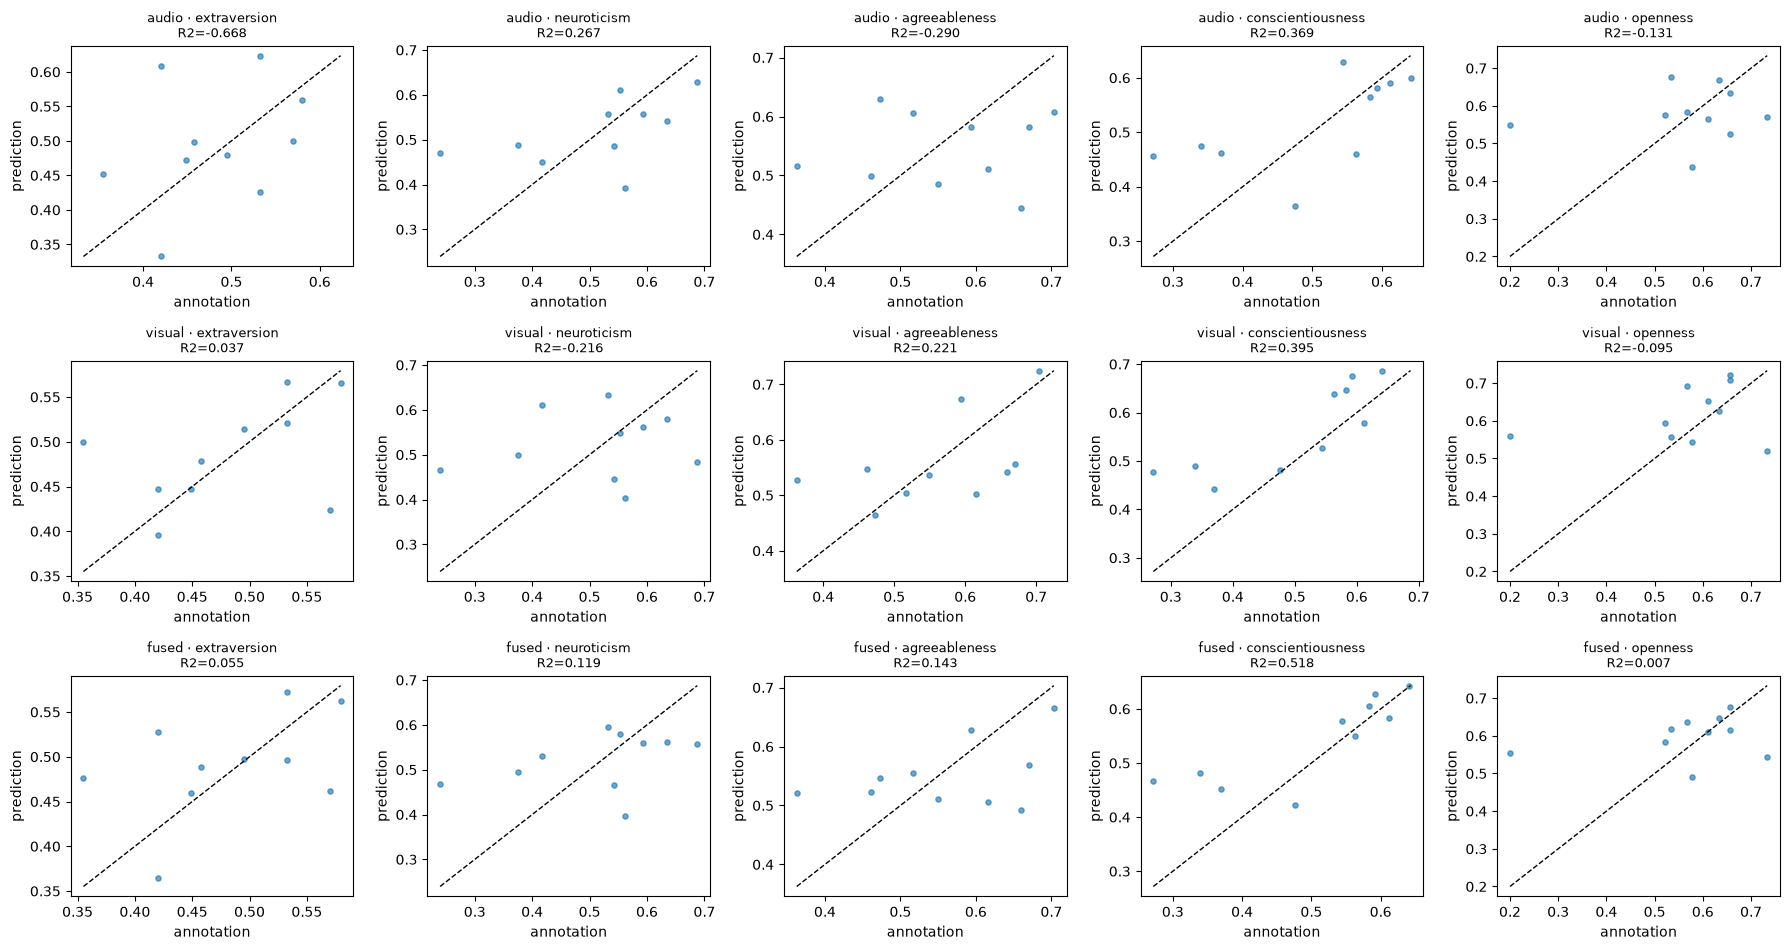

saved: /mnt/4A3ED7573ED73AA1/aa-kuliah/skripsi/app/results/eval_r2/r2_scatter_20261102_215631.png


In [ ]:
stamp = time.strftime("%Y%m%d_%H%M%S")
merged_path = os.path.join(eval_dir, f"matched_predictions_{stamp}.csv")
table_path = os.path.join(eval_dir, f"r2_summary_{stamp}.csv")
merged.to_csv(merged_path, index=False)
r2_table.to_csv(table_path)
print("saved:", merged_path)
print("saved:", table_path)

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib not installed; skipping scatter plots (the CSVs above can be plotted elsewhere).")

if plt is not None:
    fig, axes = plt.subplots(
        len(MODALITIES), len(OCEAN),
        figsize=(3.6 * len(OCEAN), 3.2 * len(MODALITIES)),
    )
    for r, modality in enumerate(MODALITIES):
        for c, trait in enumerate(OCEAN):
            ax = axes[r, c]
            x = merged[trait].to_numpy(dtype=float)
            y = merged[f"{modality}_{trait}"].to_numpy(dtype=float)
            ax.scatter(x, y, s=14, alpha=0.65)
            low = np.nanmin([x.min(), y.min()])
            high = np.nanmax([x.max(), y.max()])
            ax.plot([low, high], [low, high], "k--", linewidth=1)
            ax.set_title(
                f"{modality} \u00b7 {trait}\nR2={r2_table.loc[trait, f'r2_{modality}']:.3f}",
                fontsize=9,
            )
            ax.set_xlabel("annotation")
            ax.set_ylabel("prediction")
    fig.tight_layout()
    plot_path = os.path.join(eval_dir, f"r2_scatter_{stamp}.png")
    fig.savefig(plot_path, dpi=150)
    plt.show()
    print("saved:", plot_path)
